# Pol-ISARSpaceTarget-1.0: Feature Normalization and ResNet18 Magnitude Baseline

This notebook follows Mam's latest instruction:

1. Extract magnitude and phase features for each image.
2. Save feature matrices as NumPy arrays.
3. Plot magnitude/phase ranges before normalization.
4. Compute column-wise mean, variance, and standard deviation from training data only.
5. Try multiple normalizations using training statistics only.
6. Apply the same training statistics to validation and test.
7. Train/evaluate a normal CNN baseline: ResNet18 using magnitude only.
8. Compare what Complex CNN gives over a magnitude-only normal CNN.



In [1]:
import json
import math
import random
import re
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, List, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Dataset

try:
    from sklearn.linear_model import SGDClassifier
    from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
except Exception:
    SGDClassifier = None
    accuracy_score = confusion_matrix = f1_score = precision_score = recall_score = None

try:
    from torchvision.models import resnet18
except Exception:
    resnet18 = None


print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))




PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


## Mount Drive



In [2]:
try:
    from google.colab import drive

    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive")
except Exception as exc:
    print("Drive mount skipped or unavailable:", exc)




Mounted at /content/drive


## Configuration



In [3]:
@dataclass
class Config:
    data_root: str = "/content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0"
    output_dir: str = "/content/drive/MyDrive/drdo/outputs/polisar_feature_norm_resnet18"
    feature_size: int = 64
    image_size: int = 256
    batch_size: int = 16
    num_workers: int = 0
    seed: int = 42
    resnet_epochs: int = 15
    resnet_lr: float = 3e-4
    augmentation_noise_std: float = 0.01


cfg = Config()
local_candidate = Path.cwd() / "Pol_ISARSpaceTarget1.0"
if not Path(cfg.data_root).exists() and local_candidate.exists():
    cfg.data_root = str(local_candidate)
out_dir = Path(cfg.output_dir)
out_dir.mkdir(parents=True, exist_ok=True)
print(json.dumps(asdict(cfg), indent=2))


def seed_everything(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(cfg.seed)




{
  "data_root": "/content/drive/MyDrive/drdo/Pol_ISARSpaceTarget1.0",
  "output_dir": "/content/drive/MyDrive/drdo/outputs/polisar_feature_norm_resnet18",
  "feature_size": 64,
  "image_size": 256,
  "batch_size": 16,
  "num_workers": 0,
  "seed": 42,
  "resnet_epochs": 15,
  "resnet_lr": 0.0003,
  "augmentation_noise_std": 0.01
}


## Dataset Reader

This reader follows the dataset author's `Tools/DataReadPython.py`.
Each `.dat` file contains interleaved float32 real and imaginary values.
Four files are read for each sample: `HH`, `HV`, `VH`, `VV`.



In [4]:
POLS = ("HH", "HV", "VH", "VV")
SATELLITE_CLASSES = ("Capella", "HISEA1", "QPSSAR", "Radarsat2", "StarLink", "Worldview4")
CLASS_TO_ID = {name: idx for idx, name in enumerate(SATELLITE_CLASSES)}
DUPLICATE_RE = re.compile(r" \(\d+\)(?=\.[^.]+$)")


def is_drive_duplicate_name(name: str) -> bool:
    return bool(DUPLICATE_RE.search(name))


def infer_satellite_id(base: str) -> int:
    for class_name, class_id in CLASS_TO_ID.items():
        if base.startswith(class_name + "_"):
            return class_id
    raise ValueError(f"Could not infer class from filename base: {base}")


def split_samples(data_root: str, split: str) -> List[Tuple[Path, str]]:
    image_dir = Path(data_root) / "ImageSets" / "images" / split
    if not image_dir.exists():
        raise FileNotFoundError(f"Missing image directory: {image_dir}")

    bases = sorted(
        {
            p.name.rsplit("_", 1)[0]
            for p in image_dir.glob("*_HH.dat")
            if not is_drive_duplicate_name(p.name)
        }
    )
    samples = [(image_dir, base) for base in bases if all((image_dir / f"{base}_{pol}.dat").exists() for pol in POLS)]
    print(f"{split}: complete full-pol samples = {len(samples)}")
    return samples


def read_full_pol_complex_official_layout(image_dir: Path, base: str) -> np.ndarray:
    data_size = (256, 256, 2, 2)
    complex_data = np.zeros(data_size, dtype=np.complex64)
    for i in range(2):
        for j in range(2):
            idx = i * 2 + j
            file_path = image_dir / f"{base}_{POLS[idx]}.dat"
            combined_data = np.fromfile(file_path, dtype=np.float32)
            if combined_data.size != 256 * 256 * 2:
                raise ValueError(f"Unexpected file size for {file_path}: {combined_data.size} float32 values")
            real_part = combined_data[0::2].reshape(data_size[0:2])
            imag_part = combined_data[1::2].reshape(data_size[0:2])
            complex_data[:, :, i, j] = real_part + 1j * imag_part
    return complex_data


def polarimetric_matrix_to_channels(complex_data: np.ndarray) -> np.ndarray:
    return np.stack(
        [
            complex_data[:, :, 0, 0],
            complex_data[:, :, 0, 1],
            complex_data[:, :, 1, 0],
            complex_data[:, :, 1, 1],
        ],
        axis=0,
    ).astype(np.complex64)


train_samples = split_samples(cfg.data_root, "train")
valid_samples = split_samples(cfg.data_root, "valid")
test_samples = split_samples(cfg.data_root, "test")




train: complete full-pol samples = 1314
valid: complete full-pol samples = 162
test: complete full-pol samples = 162


## Plot Raw Magnitude and Phase Ranges

These plots are created before normalization.



{
  "magnitude_global_min": 2.4063368982751854e-05,
  "magnitude_global_max": 311.7235107421875,
  "phase_global_min_radians": -3.1415927410125732,
  "phase_global_max_radians": 3.1415927410125732,
  "phase_expected_range": "approximately [-pi, pi]"
}


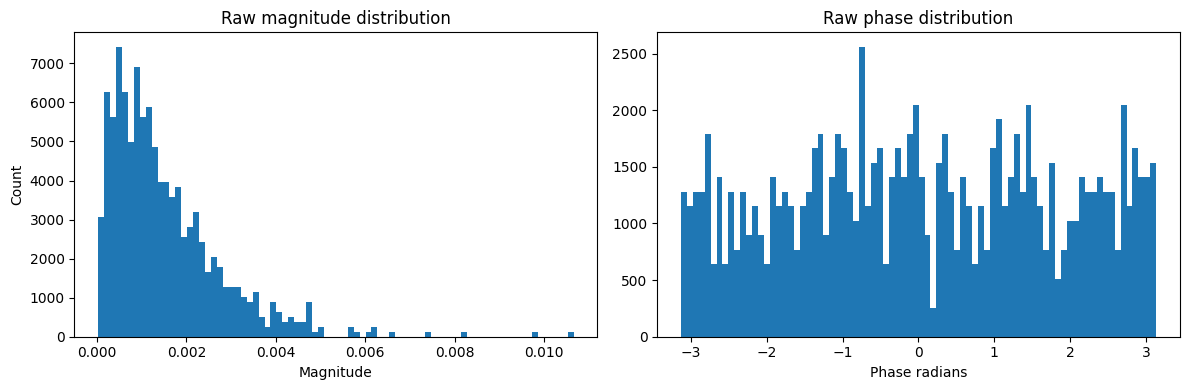

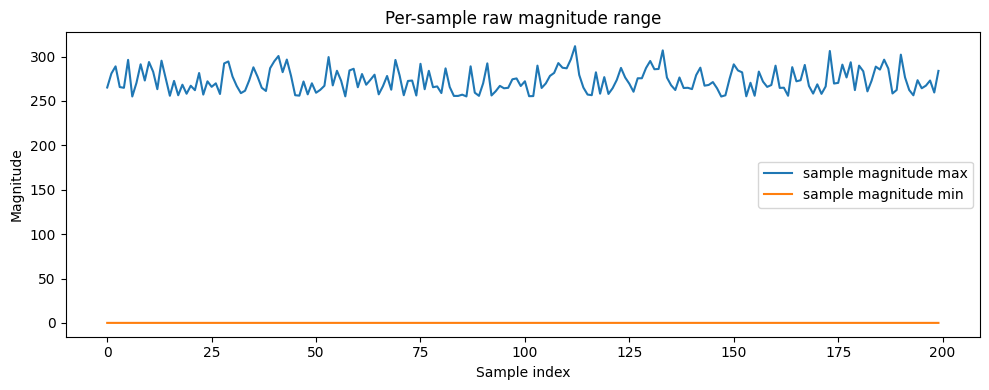

In [5]:
def collect_range_values(samples: Sequence[Tuple[Path, str]], max_samples: int | None = 200) -> Dict[str, np.ndarray]:
    chosen = list(samples if max_samples is None else samples[:max_samples])
    mag_min, mag_max, phase_min, phase_max = [], [], [], []
    mag_values, phase_values = [], []

    for image_dir, base in chosen:
        x = polarimetric_matrix_to_channels(read_full_pol_complex_official_layout(image_dir, base))
        mag = np.abs(x)
        phase = np.angle(x)
        mag_min.append(float(mag.min()))
        mag_max.append(float(mag.max()))
        phase_min.append(float(phase.min()))
        phase_max.append(float(phase.max()))
        mag_values.append(mag.reshape(-1)[::512])
        phase_values.append(phase.reshape(-1)[::512])

    return {
        "mag_min": np.array(mag_min),
        "mag_max": np.array(mag_max),
        "phase_min": np.array(phase_min),
        "phase_max": np.array(phase_max),
        "mag_values": np.concatenate(mag_values),
        "phase_values": np.concatenate(phase_values),
    }


range_data = collect_range_values(train_samples, max_samples=200)
range_summary = {
    "magnitude_global_min": float(range_data["mag_min"].min()),
    "magnitude_global_max": float(range_data["mag_max"].max()),
    "phase_global_min_radians": float(range_data["phase_min"].min()),
    "phase_global_max_radians": float(range_data["phase_max"].max()),
    "phase_expected_range": "approximately [-pi, pi]",
}
print(json.dumps(range_summary, indent=2))
(out_dir / "raw_range_summary.json").write_text(json.dumps(range_summary, indent=2))

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.hist(range_data["mag_values"], bins=80)
plt.title("Raw magnitude distribution")
plt.xlabel("Magnitude")
plt.ylabel("Count")
plt.subplot(1, 2, 2)
plt.hist(range_data["phase_values"], bins=80)
plt.title("Raw phase distribution")
plt.xlabel("Phase radians")
plt.tight_layout()
plt.savefig(out_dir / "raw_magnitude_phase_histograms.png", dpi=160)
plt.show()

plt.figure(figsize=(10, 4))
plt.plot(range_data["mag_max"], label="sample magnitude max")
plt.plot(range_data["mag_min"], label="sample magnitude min")
plt.title("Per-sample raw magnitude range")
plt.xlabel("Sample index")
plt.ylabel("Magnitude")
plt.legend()
plt.tight_layout()
plt.savefig(out_dir / "raw_magnitude_sample_ranges.png", dpi=160)
plt.show()




## Extract Feature Matrices as NumPy

Each row is one image. Columns are downsampled magnitude and phase features.

Feature vector:

`[mag_HH, mag_HV, mag_VH, mag_VV, phase_HH, phase_HV, phase_VH, phase_VV]`

downsampled to `64 x 64` and flattened.



In [6]:
def resize_np_stack(x: np.ndarray, size: int) -> np.ndarray:
    tensor = torch.from_numpy(x).float().unsqueeze(0)
    resized = F.interpolate(tensor, size=(size, size), mode="bilinear", align_corners=False).squeeze(0)
    return resized.numpy()


def extract_mag_phase_feature(image_dir: Path, base: str, feature_size: int) -> np.ndarray:
    x = polarimetric_matrix_to_channels(read_full_pol_complex_official_layout(image_dir, base))
    mag = np.abs(x).astype(np.float32)
    phase = (np.angle(x) / math.pi).astype(np.float32)
    mag_small = resize_np_stack(mag, feature_size)
    phase_small = resize_np_stack(phase, feature_size)
    return np.concatenate([mag_small.reshape(-1), phase_small.reshape(-1)]).astype(np.float32)


def build_feature_matrix(samples: Sequence[Tuple[Path, str]], split: str) -> Tuple[np.ndarray, np.ndarray, List[str]]:
    x_path = out_dir / f"X_{split}_mag_phase_{cfg.feature_size}.npy"
    y_path = out_dir / f"y_{split}.npy"
    bases_path = out_dir / f"bases_{split}.json"
    if x_path.exists() and y_path.exists() and bases_path.exists():
        print(f"Loading cached feature matrix for {split}")
        return np.load(x_path), np.load(y_path), json.loads(bases_path.read_text())

    X = np.zeros((len(samples), 8 * cfg.feature_size * cfg.feature_size), dtype=np.float32)
    y = np.zeros((len(samples),), dtype=np.int64)
    bases = []
    for idx, (image_dir, base) in enumerate(samples):
        X[idx] = extract_mag_phase_feature(image_dir, base, cfg.feature_size)
        y[idx] = infer_satellite_id(base)
        bases.append(base)
        if idx == 0 or (idx + 1) % 100 == 0 or idx + 1 == len(samples):
            print(f"{split}: extracted {idx + 1}/{len(samples)}")

    np.save(x_path, X)
    np.save(y_path, y)
    bases_path.write_text(json.dumps(bases, indent=2))
    print(f"Saved {split} feature matrix:", x_path, X.shape)
    return X, y, bases


X_train, y_train, train_bases = build_feature_matrix(train_samples, "train")
X_valid, y_valid, valid_bases = build_feature_matrix(valid_samples, "valid")
X_test, y_test, test_bases = build_feature_matrix(test_samples, "test")
print("Feature matrices:", X_train.shape, X_valid.shape, X_test.shape)




Loading cached feature matrix for train
Loading cached feature matrix for valid
Loading cached feature matrix for test
Feature matrices: (1314, 32768) (162, 32768) (162, 32768)


## Training-Only Column Statistics

These statistics are computed from `X_train` only.
The same values are then used to normalize validation and test.



In [7]:
eps = 1e-6
feature_stats = {
    "mean": X_train.mean(axis=0).astype(np.float32),
    "var": X_train.var(axis=0).astype(np.float32),
    "std": (X_train.std(axis=0) + eps).astype(np.float32),
    "min": X_train.min(axis=0).astype(np.float32),
    "max": X_train.max(axis=0).astype(np.float32),
    "median": np.median(X_train, axis=0).astype(np.float32),
    "q25": np.percentile(X_train, 25, axis=0).astype(np.float32),
    "q75": np.percentile(X_train, 75, axis=0).astype(np.float32),
}
feature_stats["iqr"] = (feature_stats["q75"] - feature_stats["q25"] + eps).astype(np.float32)
feature_stats["maxabs"] = (np.maximum(np.abs(X_train).max(axis=0), eps)).astype(np.float32)

np.savez_compressed(out_dir / "train_column_stats_mag_phase.npz", **feature_stats)
stat_summary = {
    "num_features": int(X_train.shape[1]),
    "train_rows": int(X_train.shape[0]),
    "mean_of_column_means": float(feature_stats["mean"].mean()),
    "mean_of_column_variances": float(feature_stats["var"].mean()),
    "mean_of_column_stds": float(feature_stats["std"].mean()),
}
print(json.dumps(stat_summary, indent=2))
(out_dir / "train_column_stats_summary.json").write_text(json.dumps(stat_summary, indent=2))




{
  "num_features": 32768,
  "train_rows": 1314,
  "mean_of_column_means": 1.2642344236373901,
  "mean_of_column_variances": 37.746009826660156,
  "mean_of_column_stds": 2.77486515045166
}


188

## Try Various Normalizations

All normalizers below use training statistics only.



{
  "normalization": "raw",
  "valid_accuracy": 1.0,
  "valid_f1_macro": 1.0,
  "test_accuracy": 1.0,
  "test_f1_macro": 1.0
}
{
  "normalization": "standard_z",
  "valid_accuracy": 0.9938271604938271,
  "valid_f1_macro": 0.9938250428816467,
  "test_accuracy": 0.9938271604938271,
  "test_f1_macro": 0.9938250428816465
}
{
  "normalization": "minmax_0_1",
  "valid_accuracy": 0.9938271604938271,
  "valid_f1_macro": 0.9938250428816465,
  "test_accuracy": 1.0,
  "test_f1_macro": 1.0
}
{
  "normalization": "minmax_-1_1",
  "valid_accuracy": 0.9876543209876543,
  "valid_f1_macro": 0.9876373626373627,
  "test_accuracy": 0.9938271604938271,
  "test_f1_macro": 0.9938250428816465
}
{
  "normalization": "robust_iqr",
  "valid_accuracy": 0.9938271604938271,
  "valid_f1_macro": 0.9938250428816467,
  "test_accuracy": 1.0,
  "test_f1_macro": 1.0
}
{
  "normalization": "maxabs",
  "valid_accuracy": 0.9135802469135802,
  "valid_f1_macro": 0.9111871402193983,
  "test_accuracy": 0.9629629629629629,
  "tes

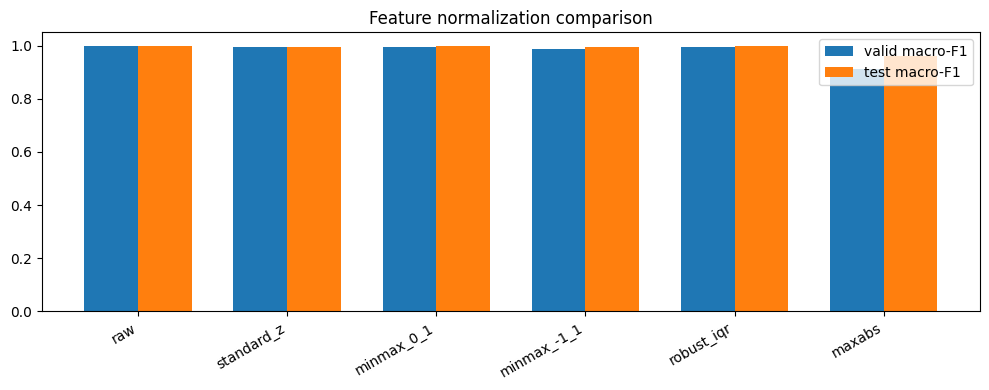

In [8]:
def normalize_features(X: np.ndarray, stats: Dict[str, np.ndarray], method: str) -> np.ndarray:
    if method == "raw":
        return X.astype(np.float32)
    if method == "standard_z":
        return ((X - stats["mean"]) / stats["std"]).astype(np.float32)
    if method == "minmax_0_1":
        return ((X - stats["min"]) / (stats["max"] - stats["min"] + eps)).astype(np.float32)
    if method == "minmax_-1_1":
        return (2.0 * (X - stats["min"]) / (stats["max"] - stats["min"] + eps) - 1.0).astype(np.float32)
    if method == "robust_iqr":
        return ((X - stats["median"]) / stats["iqr"]).astype(np.float32)
    if method == "maxabs":
        return (X / stats["maxabs"]).astype(np.float32)
    raise ValueError(f"Unknown normalization method: {method}")


def evaluate_feature_normalization(method: str) -> Dict[str, float | str]:
    if SGDClassifier is None:
        raise RuntimeError("scikit-learn is required for feature normalization experiments.")

    Xtr = normalize_features(X_train, feature_stats, method)
    Xva = normalize_features(X_valid, feature_stats, method)
    Xte = normalize_features(X_test, feature_stats, method)

    clf = SGDClassifier(loss="log_loss", alpha=1e-4, max_iter=2000, tol=1e-4, random_state=cfg.seed)
    clf.fit(Xtr, y_train)
    valid_pred = clf.predict(Xva)
    test_pred = clf.predict(Xte)

    row = {
        "normalization": method,
        "valid_accuracy": float(accuracy_score(y_valid, valid_pred)),
        "valid_f1_macro": float(f1_score(y_valid, valid_pred, average="macro")),
        "test_accuracy": float(accuracy_score(y_test, test_pred)),
        "test_f1_macro": float(f1_score(y_test, test_pred, average="macro")),
    }
    return row


normalization_methods = ["raw", "standard_z", "minmax_0_1", "minmax_-1_1", "robust_iqr", "maxabs"]
normalization_rows = []
for method in normalization_methods:
    row = evaluate_feature_normalization(method)
    normalization_rows.append(row)
    print(json.dumps(row, indent=2))

(out_dir / "normalization_experiment_results.json").write_text(json.dumps(normalization_rows, indent=2))

plt.figure(figsize=(10, 4))
labels = [row["normalization"] for row in normalization_rows]
valid_scores = [row["valid_f1_macro"] for row in normalization_rows]
test_scores = [row["test_f1_macro"] for row in normalization_rows]
xpos = np.arange(len(labels))
plt.bar(xpos - 0.18, valid_scores, width=0.36, label="valid macro-F1")
plt.bar(xpos + 0.18, test_scores, width=0.36, label="test macro-F1")
plt.xticks(xpos, labels, rotation=30, ha="right")
plt.ylim(0, 1.05)
plt.title("Feature normalization comparison")
plt.legend()
plt.tight_layout()
plt.savefig(out_dir / "normalization_comparison_macro_f1.png", dpi=160)
plt.show()




## ResNet18 Magnitude-Only Baseline

This is a normal CNN baseline. It uses only magnitude, no phase and no complex
real/imag arithmetic.



In [9]:
def compute_magnitude_train_stats(samples: Sequence[Tuple[Path, str]]) -> Dict[str, torch.Tensor]:
    sum_mag = torch.zeros(4, 1, 1)
    sumsq_mag = torch.zeros(4, 1, 1)
    count = 0
    for idx, (image_dir, base) in enumerate(samples):
        x = polarimetric_matrix_to_channels(read_full_pol_complex_official_layout(image_dir, base))
        mag = torch.from_numpy(np.abs(x).astype(np.float32))
        sum_mag += mag.sum(dim=(-2, -1), keepdim=True)
        sumsq_mag += (mag * mag).sum(dim=(-2, -1), keepdim=True)
        count += mag.shape[-2] * mag.shape[-1]
        if idx == 0 or (idx + 1) % 200 == 0 or idx + 1 == len(samples):
            print(f"magnitude stats: {idx + 1}/{len(samples)}")
    mean = sum_mag / count
    var = (sumsq_mag / count - mean * mean).clamp_min(1e-6)
    return {"mean": mean, "std": torch.sqrt(var)}


mag_train_stats = compute_magnitude_train_stats(train_samples)
print("Magnitude train stats:", {k: v.flatten().tolist() for k, v in mag_train_stats.items()})


def augment_magnitude(mag: torch.Tensor) -> torch.Tensor:
    if torch.rand(()) < 0.5:
        mag = torch.flip(mag, dims=(-1,))
    if torch.rand(()) < 0.5:
        mag = torch.flip(mag, dims=(-2,))
    k = int(torch.randint(0, 4, ()).item())
    if k:
        mag = torch.rot90(mag, k=k, dims=(-2, -1))
    if cfg.augmentation_noise_std > 0:
        mag = (mag + torch.randn_like(mag) * cfg.augmentation_noise_std).clamp_min(0)
    return mag


class MagnitudeDataset(Dataset):
    def __init__(self, samples: Sequence[Tuple[Path, str]], stats: Dict[str, torch.Tensor], augment: bool = False) -> None:
        self.samples = list(samples)
        self.stats = stats
        self.augment = augment

    def __len__(self) -> int:
        return len(self.samples)

    def __getitem__(self, index: int) -> Dict[str, torch.Tensor]:
        image_dir, base = self.samples[index]
        x = polarimetric_matrix_to_channels(read_full_pol_complex_official_layout(image_dir, base))
        mag = torch.from_numpy(np.abs(x).astype(np.float32))
        mag = (mag - self.stats["mean"]) / self.stats["std"]
        if self.augment:
            mag = augment_magnitude(mag)
        return {"x": mag, "class_id": torch.tensor(infer_satellite_id(base), dtype=torch.long), "base": base}


def collate_mag(batch: Sequence[Dict[str, torch.Tensor]]) -> Dict[str, torch.Tensor]:
    return {
        "x": torch.stack([item["x"] for item in batch]),
        "class_id": torch.stack([item["class_id"] for item in batch]),
        "base": [str(item["base"]) for item in batch],
    }


def make_mag_loader(dataset: Dataset, shuffle: bool) -> DataLoader:
    return DataLoader(
        dataset,
        batch_size=cfg.batch_size,
        shuffle=shuffle,
        num_workers=cfg.num_workers,
        pin_memory=torch.cuda.is_available(),
        collate_fn=collate_mag,
    )


def make_resnet18_magnitude(num_classes: int = 6) -> nn.Module:
    if resnet18 is None:
        raise RuntimeError("torchvision is required for ResNet18 baseline.")
    model = resnet18(weights=None)
    model.conv1 = nn.Conv2d(4, 64, kernel_size=7, stride=2, padding=3, bias=False)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
resnet_train_ds = MagnitudeDataset(train_samples, mag_train_stats, augment=True)
resnet_valid_ds = MagnitudeDataset(valid_samples, mag_train_stats, augment=False)
resnet_test_ds = MagnitudeDataset(test_samples, mag_train_stats, augment=False)
resnet_train_loader = make_mag_loader(resnet_train_ds, shuffle=True)
resnet_valid_loader = make_mag_loader(resnet_valid_ds, shuffle=False)
resnet_test_loader = make_mag_loader(resnet_test_ds, shuffle=False)

resnet_model = make_resnet18_magnitude(num_classes=len(SATELLITE_CLASSES)).to(device)
optimizer = torch.optim.Adam(resnet_model.parameters(), lr=cfg.resnet_lr)
criterion = nn.CrossEntropyLoss()


def run_resnet_epoch(loader: DataLoader, train: bool, phase: str) -> Dict[str, float]:
    resnet_model.train(train)
    total_loss = 0.0
    targets, preds = [], []
    for batch_idx, batch in enumerate(loader, start=1):
        x = batch["x"].to(device)
        y = batch["class_id"].to(device)
        with torch.set_grad_enabled(train):
            logits = resnet_model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
        total_loss += float(loss.detach().cpu())
        targets.extend(y.detach().cpu().tolist())
        preds.extend(logits.detach().argmax(dim=1).cpu().tolist())
        if batch_idx == 1 or batch_idx == len(loader) or batch_idx % 20 == 0:
            print(f"{phase} [{batch_idx:04d}/{len(loader):04d}] loss={total_loss / batch_idx:.4f}")
    return {
        "loss": total_loss / max(len(loader), 1),
        "accuracy": float(accuracy_score(targets, preds)),
        "f1_macro": float(f1_score(targets, preds, average="macro")),
    }


resnet_history = []
for epoch in range(cfg.resnet_epochs):
    t0 = time.time()
    train_metrics = run_resnet_epoch(resnet_train_loader, train=True, phase=f"resnet epoch {epoch + 1} train")
    valid_metrics = run_resnet_epoch(resnet_valid_loader, train=False, phase=f"resnet epoch {epoch + 1} valid")
    row = {
        "epoch": epoch + 1,
        **{f"train_{k}": v for k, v in train_metrics.items()},
        **{f"valid_{k}": v for k, v in valid_metrics.items()},
        "seconds": time.time() - t0,
    }
    resnet_history.append(row)
    print(json.dumps(row, indent=2))

test_metrics = run_resnet_epoch(resnet_test_loader, train=False, phase="resnet test")
print("ResNet18 magnitude-only test metrics:")
print(json.dumps(test_metrics, indent=2))

(out_dir / "resnet18_magnitude_history.json").write_text(json.dumps(resnet_history, indent=2))
(out_dir / "resnet18_magnitude_test_metrics.json").write_text(json.dumps(test_metrics, indent=2))




magnitude stats: 1/1314
magnitude stats: 200/1314
magnitude stats: 400/1314
magnitude stats: 600/1314
magnitude stats: 800/1314
magnitude stats: 1000/1314
magnitude stats: 1200/1314
magnitude stats: 1314/1314
Magnitude train stats: {'mean': [3.0613393783569336, 2.8072009086608887, 1.4706710577011108, 2.765376567840576], 'std': [10.523825645446777, 11.589123725891113, 5.422358989715576, 9.5582857131958]}
resnet epoch 1 train [0001/0083] loss=1.8104
resnet epoch 1 train [0020/0083] loss=0.9868
resnet epoch 1 train [0040/0083] loss=0.7503
resnet epoch 1 train [0060/0083] loss=0.6075
resnet epoch 1 train [0080/0083] loss=0.5487
resnet epoch 1 train [0083/0083] loss=0.5571
resnet epoch 1 valid [0001/0011] loss=4.7118
resnet epoch 1 valid [0011/0011] loss=7.1566
{
  "epoch": 1,
  "train_loss": 0.5571493282016501,
  "train_accuracy": 0.7929984779299848,
  "train_f1_macro": 0.7887065820461747,
  "valid_loss": 7.156587826257397,
  "valid_accuracy": 0.32098765432098764,
  "valid_f1_macro": 0.228

102

## Research Interpretation

A Complex CNN is expected to be useful when phase and real/imaginary
relationships carry class information. A normal magnitude-only CNN discards
phase and uses only scattering intensity.

If ResNet18 magnitude-only performs close to the Complex CNN on the official
split, then the official split may be dominated by magnitude/scattering-shape
cues. In that case, the Complex CNN should be justified using harder tests:
phase-only ablation, magnitude-only ablation, unseen elevation/azimuth splits,
low-SNR robustness, and target detection settings.

If Complex CNN performs better under these harder settings, then the benefit is
not just accuracy on the official split; it is better use of polarimetric
complex information and better robustness.
